# Are NBFNet's Path Explanations Actually Faithful?

CAP 6938 term project (research track). Shadi Khodagholi, UCF.

NBFNet explains its answers with paths through the graph. I check whether the model really uses those paths by deleting or changing edges and running it again.

Runs on a free CPU runtime. **Runtime > Run all** is fine; the long runs at the end are off. This copy already has the outputs of a full run saved in it.

## 1. Setup

Get the code.

In [1]:
import os, subprocess
REPO = 'https://github.com/shadi97kh/nbfnet-path-faithfulness.git'
WORK = '/content/nbfnet-path-faithfulness'
if not os.path.exists(WORK):
    subprocess.run(['git', 'clone', '-q', REPO, WORK], check=True)
os.chdir(WORK)
print('code is in', WORK)

code is in /content/nbfnet-path-faithfulness


Install PyTorch Geometric and ULTRA. The frozen checkpoint comes with ULTRA, so nothing gets trained.

In [2]:
import sys, torch
os.environ['CUDA_VISIBLE_DEVICES'] = ''    # everything runs on CPU
os.environ['PYTHONWARNINGS'] = 'ignore'
pip = [sys.executable, '-m', 'pip', 'install', '-q', '--disable-pip-version-check']
subprocess.run(pip + ['torch_geometric', 'easydict', 'ninja'], check=True)

def scatter_works():
    test = 'import torch_scatter; torch_scatter.scatter_add'
    return subprocess.run([sys.executable, '-c', test], capture_output=True).returncode == 0

major, minor = torch.__version__.split('+')[0].split('.')[:2]
if not scatter_works():
    wheels = f'https://data.pyg.org/whl/torch-{major}.{minor}.0+cpu.html'
    subprocess.run(pip + ['--only-binary=:all:', 'torch_scatter', '-f', wheels], capture_output=True)
if scatter_works():
    print('torch_scatter: prebuilt wheel')
else:
    # no wheel for this torch version, so use the pure-PyTorch copy
    subprocess.run([sys.executable, '-m', 'pip', 'uninstall', '-y', '-q', 'torch_scatter'], capture_output=True)
    subprocess.run(pip + ['./torch_scatter_shim'], check=True)
    print('torch_scatter: no wheel for torch', torch.__version__, 'so using the pure-PyTorch copy')

if not os.path.exists('ultra/ckpts/ultra_4g.pth'):
    subprocess.run(['git', 'clone', '-q', 'https://github.com/DeepGraphLearning/ULTRA.git', 'ultra'], check=True)
    subprocess.run(['git', '-C', 'ultra', 'checkout', '-q', '427966ad8ed60420eef034063d44f3153addff90'], check=True)
print('torch', torch.__version__, '| ULTRA ready')

torch_scatter: prebuilt wheel
torch 2.14.1+cu130 | ULTRA ready


Load the model once. The first time compiles a kernel, so it takes about a minute.

In [3]:
!python -m pathfaith.warmup --dataset CoDExSmall

CoDExSmall: 2,034 entities, 65,776 edges, 42 relations
ultra_4g.pth: 168,705 parameters, all frozen
graph ready in 3s, first forward pass (kernel compile) in 0s


## 2. Demo

**Run 1:** five queries on CoDEx-S, which the model never saw in training. For each one you get the answer and NBFNet's top paths, then a few edits to the graph, with the model re-run after each one.

In [4]:
!python -m pathfaith.demo --n 5 --seed 0 --color always

== Are NBFNet's path explanations actually faithful?  live run =========


  graph       CoDExSmall: 2,034 entities, 42 relations, 65,776 edges
  checkpoint  ultra_4g.pth: 168,705 parameters, all frozen, no training
  loaded in 1.7s on CPU



== query 1 of 5 ========================================================


  Samuel R. Delany  -[religion]->  ?
  model answers atheism   rank 1, p = 0.507



  NBFNet's own explanation (gradient, top 3 paths):
    1. weight 0.131   2 hops
         Samuel R. Delany -[influenced by]-> Virginia Woolf
         Virginia Woolf -[religion]-> atheism
    2. weight 0.091   4 hops
         Samuel R. Delany -[influenced by]-> Virginia Woolf
         Virginia Woolf <-[influenced by]- Samuel R. Delany
         Samuel R. Delany -[influenced by]-> Virginia Woolf
         Virginia Woolf -[religion]-> atheism
    3. weight 0.088   3 hops
         Samuel R. Delany -[influenced by]-> Virginia Woolf
         Virginia Woolf -[influenced by]-> George Eliot
         George Eliot -[religion]-> atheism


    (that gradient is taken on a model that gives this answer p = 0.499; the deployed model gives 0.507)

  intervene on the graph (each line is a fresh forward pass):


... (31 outputs left out)

    delete only the busiest edge            p 0.096 -> 0.096   rank 1 -> 1     none of the effect
      that edge, in 3 of 3 paths: Idina Menzel -[country of citizenship]-> United States of America


    reroute the last hop to pianist         film actor -0.002   pianist +0.002


    neuromodulate the [country of citizenship] channel (3,296 edges)
      gain 1 -> 0.5 -> 0                    p 0.096 -> 0.096 -> 0.094
      gradient at gain 1 predicts           p -> 0.096 at gain 0   wrong sign
  (2.2s for this query)

== these live queries ==================================================
  5 queries attempted, 5 completed every intervention, 0 failed.
  deleting the explanation removed 18% of p(answer) on average; random edges removed 0%.
  the answer fell out of the top 10 in 0 of 5.
  silencing the main channel removed 27% of p on average; the gradient had the right sign in 1 of 5.
  total 14s

== the same pipeline, at benchmark scale ===============================


                                          WN18RR             FB15k-237               CoDEx-S               NELL23k
                                  in pre-training        in pre-training               held out               held out
  queries                                    200                   200                   200                   200
  delete shortlist          +0.858 [+0.81,+0.90]  +0.259 [+0.21,+0.30]  +0.427 [+0.39,+0.47]  +0.368 [+0.29,+0.44]
  delete random edges       +0.000 [-0.00,+0.00]  -0.000 [-0.00,+0.00]  +0.000 [-0.00,+0.00]  +0.007 [+0.01,+0.01]
  Kendall tau               -0.009 [-0.05,+0.04]  +0.048 [+0.01,+0.09]  +0.076 [+0.04,+0.11]  +0.041 [-0.02,+0.10]
  top path is best          +0.253 [+0.20,+0.31]  +0.080 [+0.04,+0.12]  +0.125 [+0.08,+0.17]  +0.306 [+0.24,+0.37]
    chance rate             +0.280 [+0.23,+0.33]  +0.057 [+0.05,+0.06]  +0.053 [+0.05,+0.05]  +0.307 [+0.26,+0.36]
  paths share one edge      +0.884 [+0.86,+0.91]  +0.734 [+0.70,+0.77]  +0.7

**Run 2:** three different queries.

In [5]:
!python -m pathfaith.demo --n 3 --seed 7 --no-benchmark --color always

== Are NBFNet's path explanations actually faithful?  live run =========


  graph       CoDExSmall: 2,034 entities, 42 relations, 65,776 edges
  checkpoint  ultra_4g.pth: 168,705 parameters, all frozen, no training
  loaded in 2.0s on CPU



== query 1 of 3 ========================================================


  Federated States of Micronesia  -[member of]->  ?
  model answers UNESCO   rank 1, p = 0.123



  NBFNet's own explanation (gradient, top 3 paths):
    1. weight 0.184   2 hops
         Federated States of Micronesia -[diplomatic relation]-> Marshall Islands
         Marshall Islands -[member of]-> UNESCO
    2. weight 0.183   2 hops
         Federated States of Micronesia -[diplomatic relation]-> Palau
         Palau -[member of]-> UNESCO
    3. weight 0.180   2 hops
         Federated States of Micronesia <-[diplomatic relation]- Marshall Islands
         Marshall Islands -[member of]-> UNESCO


    (that gradient is taken on a model that gives this answer p = 0.003; the deployed model gives 0.123)

  intervene on the graph (each line is a fresh forward pass):
    delete those 3 paths (10 edges)         p 0.123 -> 0.075   rank 1 -> 2     partly

... (14 outputs left out)

    delete those 3 paths (6 edges)          p 0.015 -> 0.007   rank 1 -> 87    load-bearing


    delete 6 random edges instead           p 0.015 -> 0.015   rank 1 -> 1     control
    delete only the busiest edge            p 0.015 -> 0.007   rank 1 -> 86    99% of the effect
      that edge, in 3 of 3 paths: Denmark -[diplomatic relation]-> Mexico


    reroute the last hop to United States o~ Denmark -0.009   United States~ +0.000


    neuromodulate the [diplomatic relation] channel (11,126 edges)
      gain 1 -> 0.5 -> 0                    p 0.015 -> 0.019 -> 0.003
      gradient at gain 1 predicts           p -> 0.019 at gain 0   wrong sign
  (2.5s for this query)

== these live queries ==================================================
  3 queries attempted, 3 completed every intervention, 0 failed.
  deleting the explanation removed 60% of p(answer) on average; random edges removed 0%.
  the answer fell out of the top 10 in 1 of 3.
  silencing the main channel removed 93% of p on average; the gradient had the right sign in 0 of 3.
  total 10s



Optional: two queries on WordNet (it downloads the graph first).

In [6]:
!python -m pathfaith.demo --dataset WN18RR --n 2 --no-benchmark --color always

== Are NBFNet's path explanations actually faithful?  live run =========


  graph       WN18RR: 40,943 entities, 11 relations, 173,670 edges
  checkpoint  ultra_4g.pth: 168,705 parameters, all frozen, no training
  loaded in 3.6s on CPU



== query 1 of 2 ========================================================


  sociology.n.01  -[derivationally related form]->  ?
  model answers sociologist.n.01   rank 1, p = 0.196



  NBFNet's own explanation (gradient, top 3 paths):
    1. weight 1.488   1 hop
         sociology.n.01 <-[derivationally related form]- sociologist.n.01
    2. weight 0.384   3 hops
         sociology.n.01 <-[synset domain topic of]- mores.n.01
         mores.n.01 -[synset domain topic of]-> sociology.n.01
         sociology.n.01 <-[derivationally related form]- sociologist.n.01
    3. weight 0.154   5 hops
         sociology.n.01 <-[synset domain topic of]- mores.n.01
         mores.n.01 -[synset domain topic of]-> sociology.n.01
         sociology.n.01 <-[synset domain topic of]- mores.n.01
         mores.n.01 -[synset domain topic of]-> sociology.n.01
         sociology.n.01 <-[derivationally related form]- sociologist.n.01


    (that gradient is taken on a model that gives this answer p = 0.002; the deployed model gives 0.196)

  intervene on the graph (each line is a fresh forward pass):


... (10 outputs left out)

    delete only the busiest edge            p 0.033 -> 0.000   rank 1 -> 135   100% of the effect
      that edge, in 3 of 3 paths: orchidaceae.n.01 -[member meronym]-> genus_pogonia.n.01


    reroute the last hop to orchidaceae.n.01 monocot_genus~ -0.000   orchidaceae.n~ +0.000


    neuromodulate the [member meronym] channel (14,804 edges)
      gain 1 -> 0.5 -> 0                    p 0.033 -> 0.022 -> 0.001
      gradient at gain 1 predicts           p -> 0.020 at gain 0   right sign
  (8.6s for this query)



== these live queries ==================================================
  2 queries attempted, 2 completed every intervention, 0 failed.
  deleting the explanation removed 100% of p(answer) on average; random edges removed 0%.
  the answer fell out of the top 10 in 2 of 2.
  silencing the main channel removed 51% of p on average; the gradient had the right sign in 1 of 2.
  total 21s



## 3. Re-run the recorded benchmark

The model gives the same output every time, so re-running the first few benchmark queries should give back exactly the saved numbers.

As released:

In [7]:
!rm -rf check && mkdir -p check
!python -m pathfaith.run_experiment --dataset CoDExSmall --n 5 --pool 20 --topk 5 --seed 0 --path-controls 0 --out check/paths_codexsmall.jsonl
!python -m pathfaith.compare_runs --new check/paths_codexsmall.jsonl --ref results/paths_codexsmall_seed0.jsonl

CoDExSmall | 2034 entities | 65776 edges | ckpt ultra_4g.pth


Load rspmm extension. This may take a while...


selected 5 queries ranked <= 10 out of 7 scanned, in 0s


[1/5] h=711 r=8 t=915 base_rank=4 comp=0.0418 bottleneck=0.40 6s


[2/5] h=1794 r=21 t=465 base_rank=1 comp=0.1734 bottleneck=1.00 6s


[3/5] h=1113 r=2 t=642 base_rank=6 comp=0.0421 bottleneck=0.80 5s


[4/5] h=931 r=2 t=178 base_rank=1 comp=0.0289 bottleneck=0.70 5s


[5/5] h=372 r=2 t=644 base_rank=2 comp=0.0047 bottleneck=0.50 6s
wrote check/paths_codexsmall.jsonl in 28s total


5 queries re-run; 5 are in the record; 5 of 5 reproduce every recorded number to within 0.0001 (largest gap 0.0e+00)


With my fix:

In [8]:
!python -m pathfaith.run_experiment --dataset CoDExSmall --n 5 --pool 20 --topk 5 --seed 0 --path-controls 0 --corrected --out check/paths_codexsmall_fixed.jsonl
!python -m pathfaith.compare_runs --new check/paths_codexsmall_fixed.jsonl --ref results/paths_codexsmall_fixed_seed0.jsonl

CoDExSmall | 2034 entities | 65776 edges | ckpt ultra_4g.pth


Load rspmm extension. This may take a while...


selected 5 queries ranked <= 10 out of 7 scanned, in 0s


[1/5] h=711 r=8 t=915 base_rank=4 comp=0.0488 bottleneck=0.45 6s


[2/5] h=1794 r=21 t=465 base_rank=1 comp=0.2740 bottleneck=1.00 5s


[3/5] h=1113 r=2 t=642 base_rank=6 comp=0.0516 bottleneck=0.70 6s


[4/5] h=931 r=2 t=178 base_rank=1 comp=0.0167 bottleneck=0.45 6s


[5/5] h=372 r=2 t=644 base_rank=2 comp=0.0017 bottleneck=0.65 6s
wrote check/paths_codexsmall_fixed.jsonl in 29s total


5 queries re-run; 5 are in the record; 5 of 5 reproduce every recorded number to within 0.0001 (largest gap 0.0e+00)


The bug: the explanation's gradient comes from a copy of the model with its messages running backwards. This prints the score gap, and shows the fix closes it.

In [9]:
!python -m pathfaith.direction_check --dataset CoDExSmall --n 3 --keep-scores 0 --out check/direction_codexsmall.jsonl

Load rspmm extension. This may take a while...


[1/3] score gap released 7.51 corrected 2.9e-06  fd +5.27e-02 released +4.04e-03 corrected +5.25e-02 3.5s


[2/3] score gap released 4.73 corrected 2.9e-06  fd -5.16e-02 released -1.17e-01 corrected -5.34e-02 3.5s


[3/3] score gap released 9.02 corrected 3.8e-06  fd +4.62e-03 released +2.29e-03 corrected +4.82e-03 3.8s
wrote check/direction_codexsmall.jsonl


Link prediction on all of CoDEx-S, about 2 minutes. The ULTRA paper reports an MRR of 0.472.

In [10]:
!python -m pathfaith.run_baseline --dataset CoDExSmall --n 0 --batch-size 8 --out check/baseline_codexsmall.json 2>&1 | grep -E '"(n_triples|mrr|hits@1|hits@10)"'

  "n_triples": 1828,
  "mrr": 0.4637776017189026,
  "hits@1": 0.36050328612327576,
  "hits@10": 0.6652078628540039,


Are 200 queries per graph enough? This only reads the saved results.


WN18RR
  delete shortlist (share of p removed)    n= 200  +0.858 [+0.816, +0.898]  +/-0.041   split-half gap p95 0.086   5-query blocks span [+0.53, +1.00]
  one edge recovers (share of effect)      n= 186  +0.650 [+0.583, +0.716]  +/-0.067   split-half gap p95 0.140   5-query blocks span [+0.17, +1.09]
  paths sharing one edge                   n= 200  +0.884 [+0.856, +0.909]  +/-0.027   split-half gap p95 0.055   5-query blocks span [+0.52, +1.00]
  top path minus chance                    n= 194  -0.028 [-0.079, +0.025]  +/-0.052   split-half gap p95 0.102   5-query blocks span [-0.51, +0.33]

FB15k-237
  delete shortlist (share of p removed)    n= 200  +0.259 [+0.214, +0.304]  +/-0.045   split-half gap p95 0.091   5-query blocks span [-0.37, +0.64]
  one edge recovers (share of effect)      n= 136  +0.025 [-0.016, +0.066]  +/-0.041   split-half gap p95 0.081   5-query blocks span [-0.23, +0.25]
  paths sharing one edge                   n= 200  +0.734 [+0.701, +0.769]  +/-0.034   

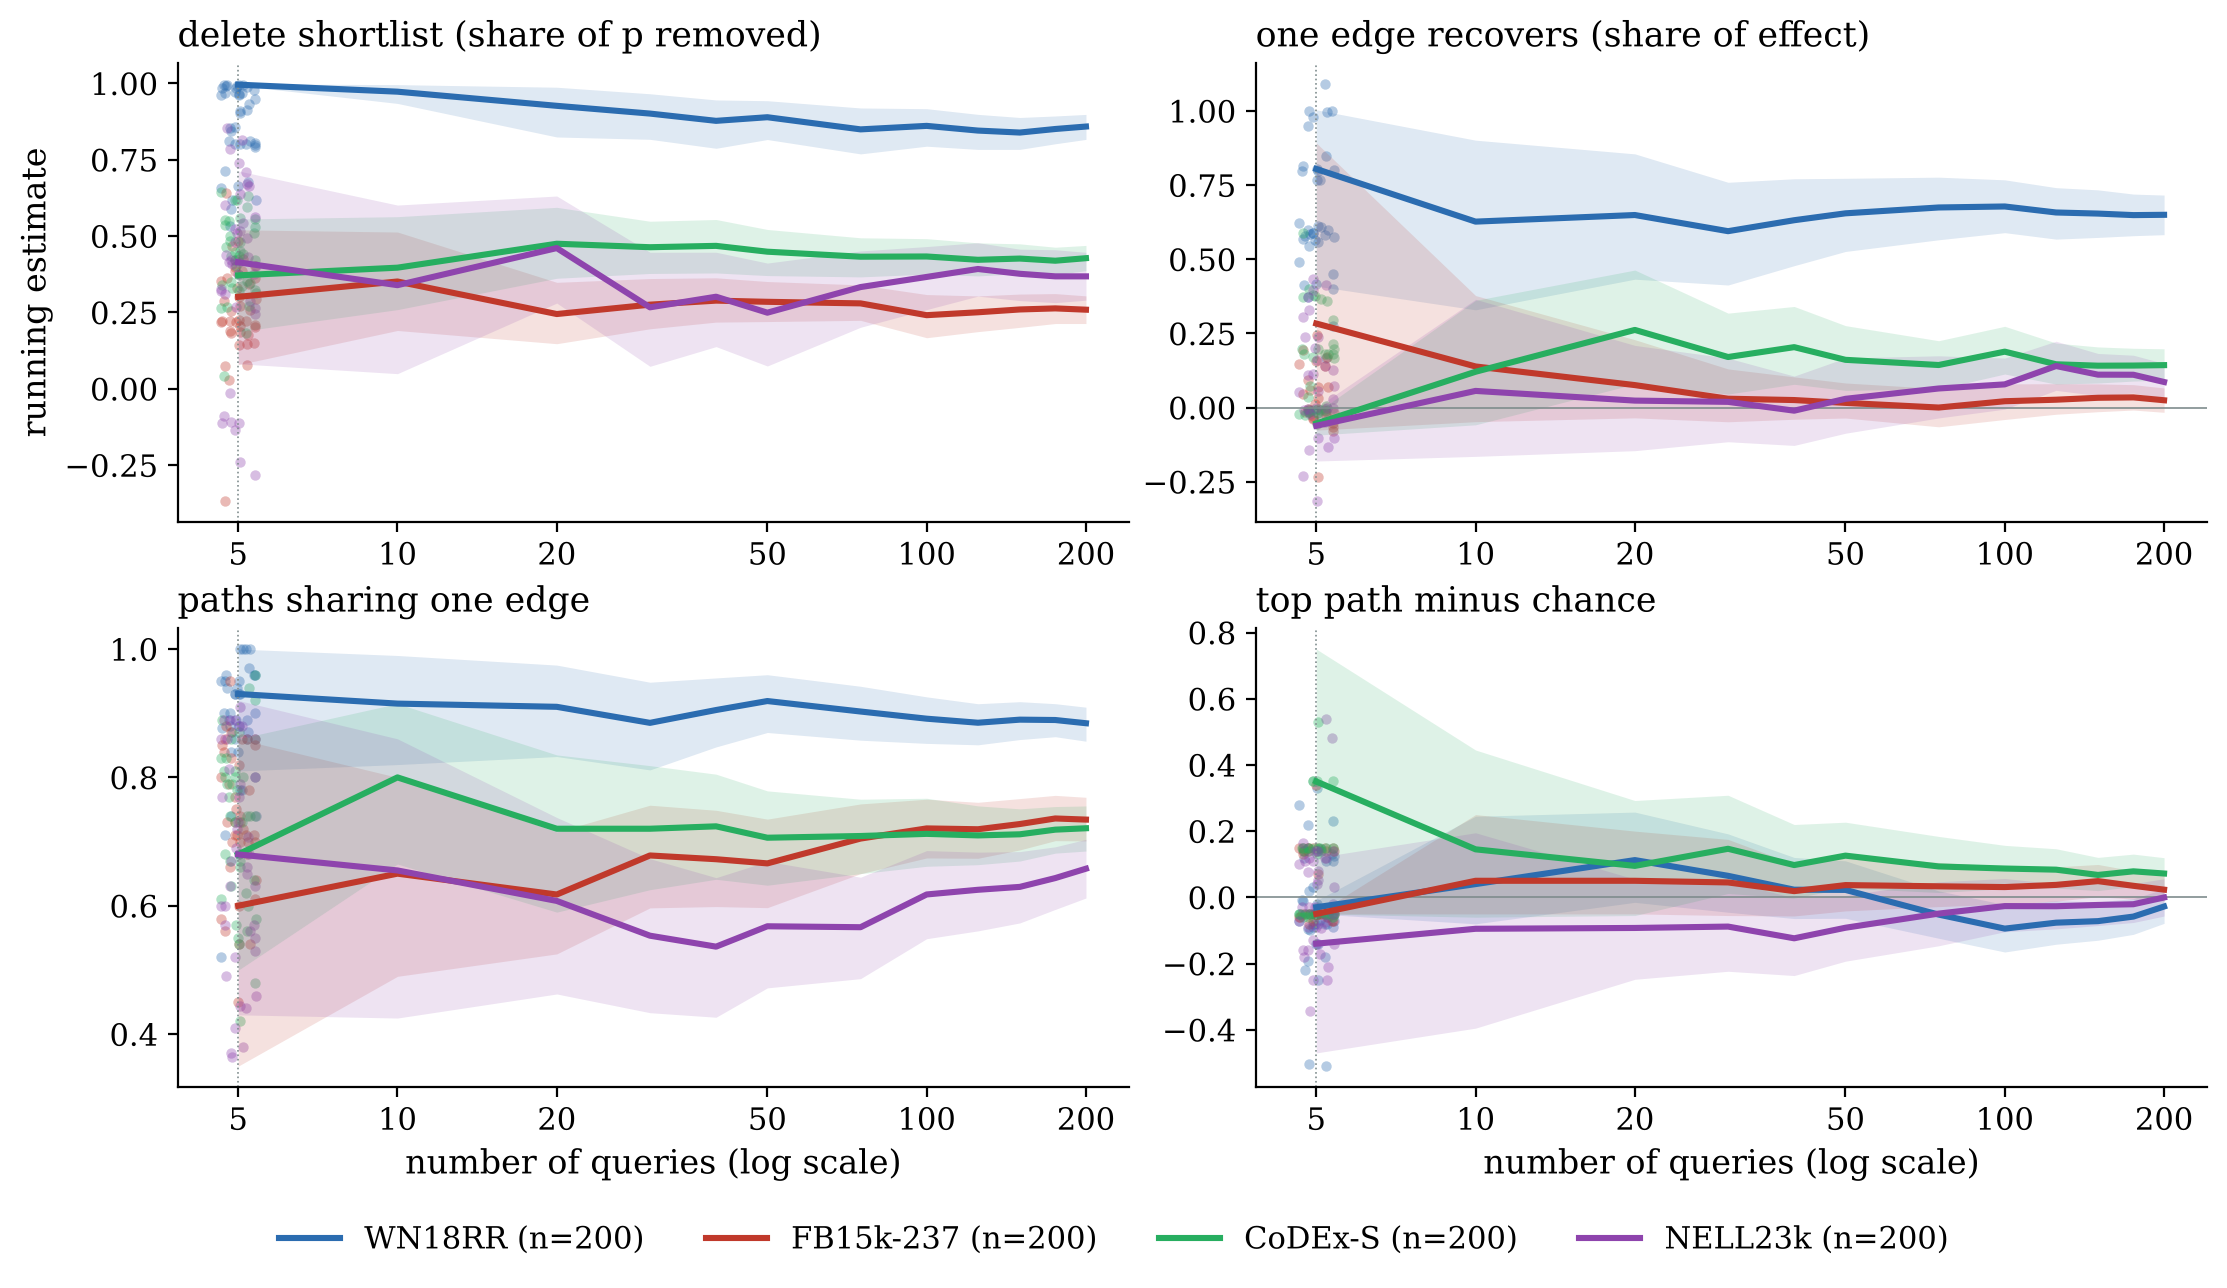

In [11]:
!python -m pathfaith.reliability
from pathfaith.figures import fig_convergence
from IPython.display import Image, display
fig_convergence('check/convergence.png', figsize=(11.07, 6.32), big=True)
display(Image('check/convergence.png'))

## 4. Neuromodulation

In ULTRA, each relation type has one vector that scales every edge of that type, a bit like a neuromodulator in the brain (the idea is from Bull et al., NeurIPS 2025). I turn that gain from 1 down to 0 and see what happens. Code: `pathfaith/neuromod.py`. Report: Section 7.5.

Live on 3 queries, checked against the saved run:

In [12]:
!python -m pathfaith.neuromod --dataset CoDExSmall --n 3 --out check/neuromod_codexsmall.jsonl
!python -m pathfaith.compare_runs --new check/neuromod_codexsmall.jsonl --ref results/neuromod_codexsmall_seed0.jsonl

CoDExSmall: 3 benchmark queries, 0 already done


Load rspmm extension. This may take a while...


[1/3] h=711 r=8 t=915 explained channels 5  best silencing 0.65  check gap 0.0e+00  8s


[2/3] h=1794 r=21 t=465 explained channels 4  best silencing 0.90  check gap 0.0e+00  8s


[3/3] h=1113 r=2 t=642 explained channels 1  best silencing 0.90  check gap 0.0e+00  7s
wrote check/neuromod_codexsmall.jsonl in 23s


3 queries re-run; 3 are in the record; 3 of 3 reproduce every recorded number to within 0.0001 (largest gap 3.2e-07)


Saved results on all four graphs:

In [13]:
import pandas as pd
from pathfaith.analyze_neuromod import rows_of, summarize
rows_shown = {
    'silence_best': 'silence the strongest channel the paths use: share of p removed',
    'silence_random': 'silence a random channel: share of p removed',
    'half_dose': 'share of that effect already there at half gain (a straight line gives 0.5)',
    'switch_like': 'channels with under a quarter of the effect at half gain',
    'sign_agree': 'gradient at gain 1 has the right sign',
    'top_is_query_rel': 'strongest channel is the query relation itself'}
table = {}
for name, tag in [('WN18RR', 'wn18rr'), ('FB15k-237', 'fb15k237'), ('CoDEx-S', 'codexsmall'), ('NELL23k', 'nell23k')]:
    _, rows = rows_of(f'results/neuromod_{tag}_seed0.jsonl')
    s, _, _ = summarize(rows)
    table[f'{name} ({len(rows)} queries)'] = {text: round(s[key][0], 3) for key, text in rows_shown.items()}
pd.set_option('display.max_colwidth', None)
pd.DataFrame(table)

,WN18RR (100 queries),FB15k-237 (50 queries),CoDEx-S (200 queries),NELL23k (200 queries)
silence the strongest channel the paths use: share of p removed,0.995,0.770,0.895,0.895
silence a random channel: share of p removed,0.020,-0.000,0.002,0.101
share of that effect already there at half gain (a straight line gives 0.5),0.285,0.226,0.189,0.027
channels with under a quarter of the effect at half gain,0.433,0.425,0.517,0.545
gradient at gain 1 has the right sign,0.592,0.649,0.608,0.739
strongest channel is the query relation itself,0.920,0.857,0.965,0.715


Dose-response curves:

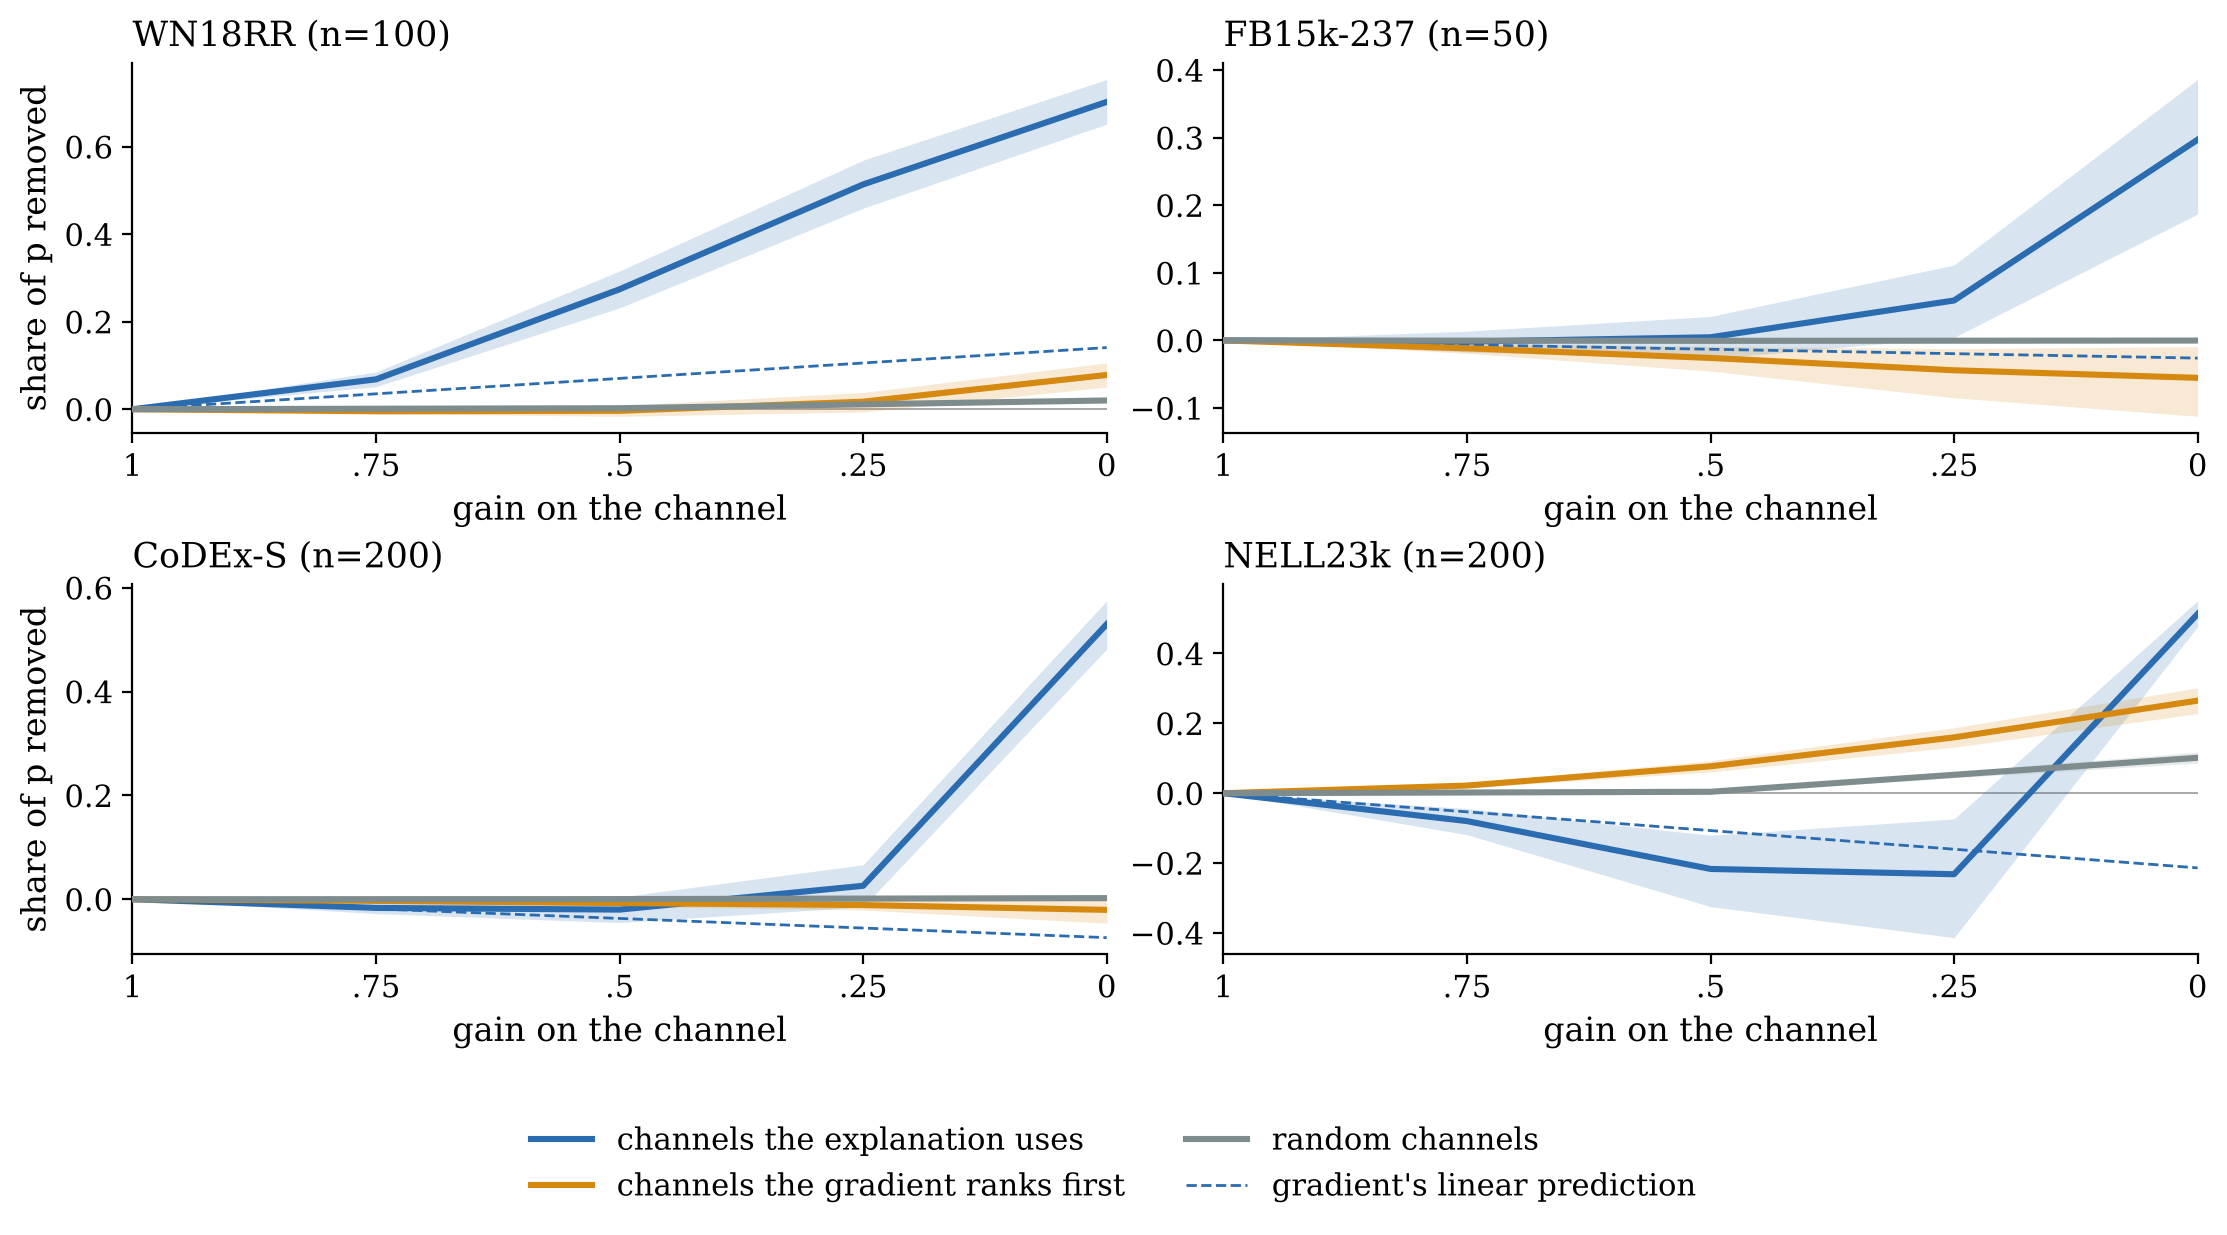

In [14]:
from pathfaith.figures import fig_dose_response
from IPython.display import Image, display
fig_dose_response('check/dose_response.png', figsize=(11.07, 6.0), big=True)
display(Image('check/dose_response.png', width=950))

The full run on 200 queries takes about an hour, so it's off:

In [15]:
RUN_CHANNELS = False
if RUN_CHANNELS:
    !python -m pathfaith.neuromod --dataset CoDExSmall --n 200 --out check/neuromod_codexsmall.jsonl
    !python -m pathfaith.analyze_neuromod check/neuromod_codexsmall.jsonl
    !python -m pathfaith.compare_runs --new check/neuromod_codexsmall.jsonl --ref results/neuromod_codexsmall_seed0.jsonl
else:
    print('switched off: set RUN_CHANNELS = True to run it')

switched off: set RUN_CHANNELS = True to run it


## 5. Every figure

Redraws every figure in the report and the slides from the saved results (no model needed), and zips them into `figures.zip`.

12 report figures and 13 slide figures written


### In the report

`report/figs/direction.pdf`

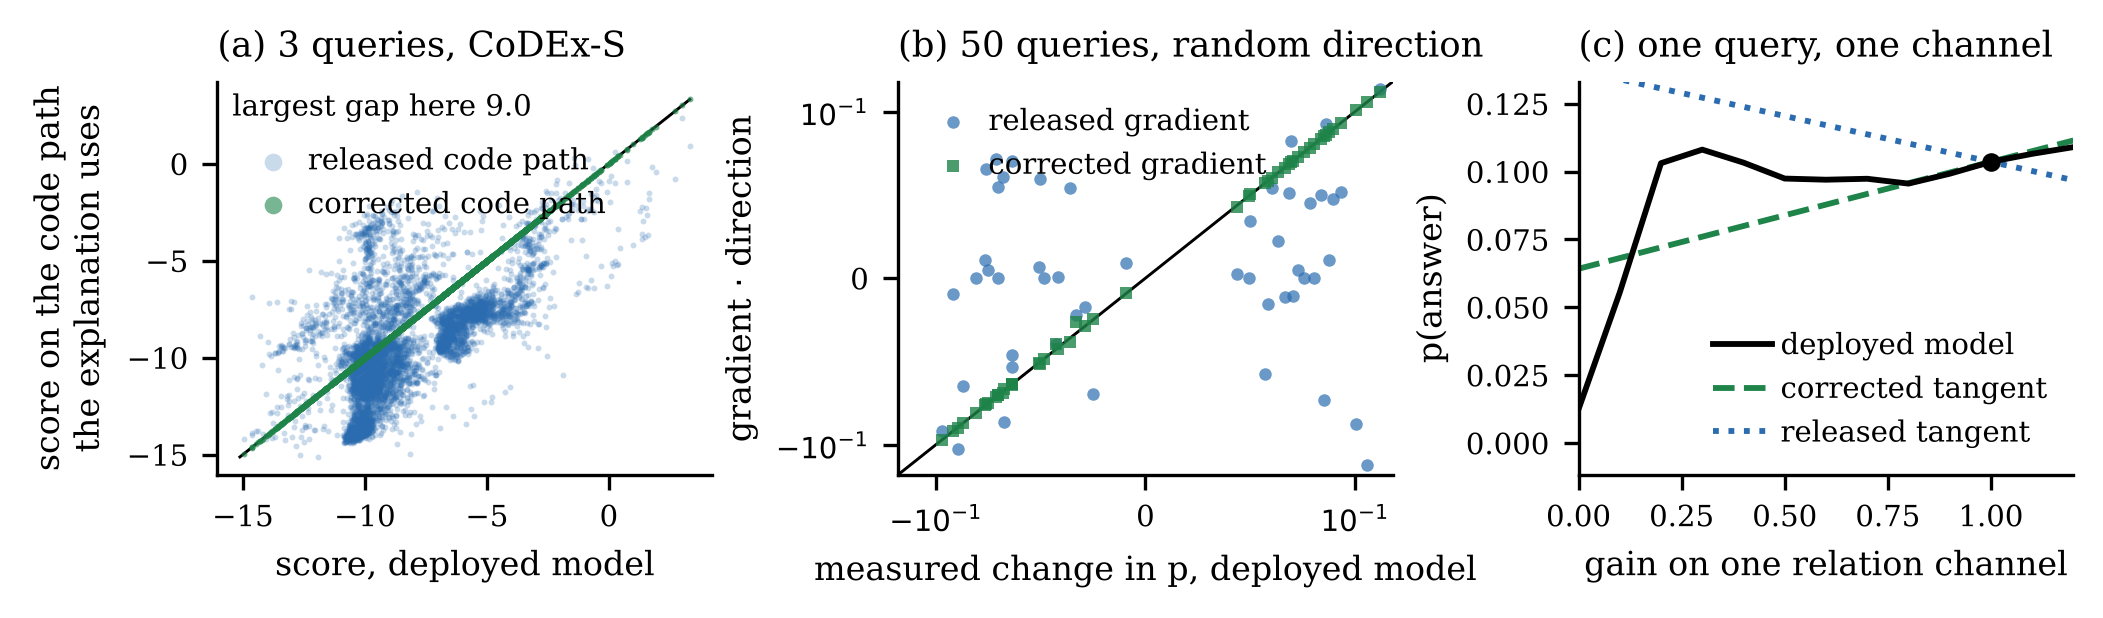

`report/figs/convergence.pdf`

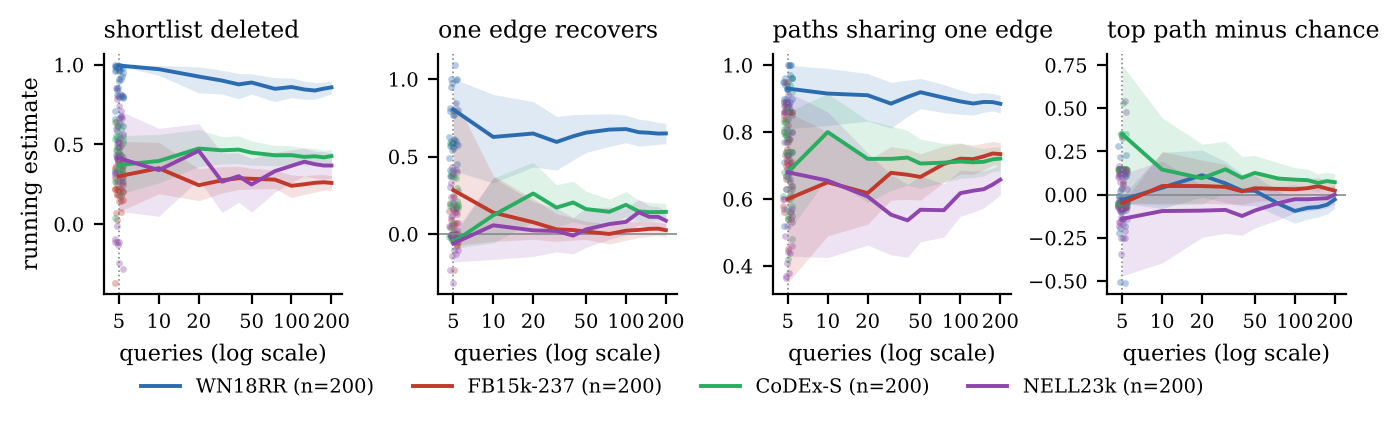

`report/figs/rank_vs_drop.pdf`

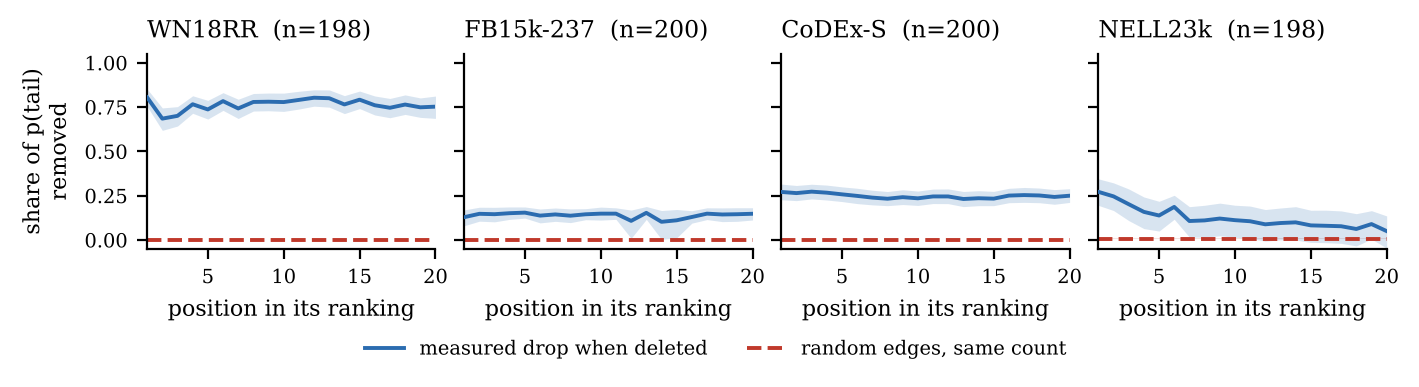

`report/figs/robustness.pdf`

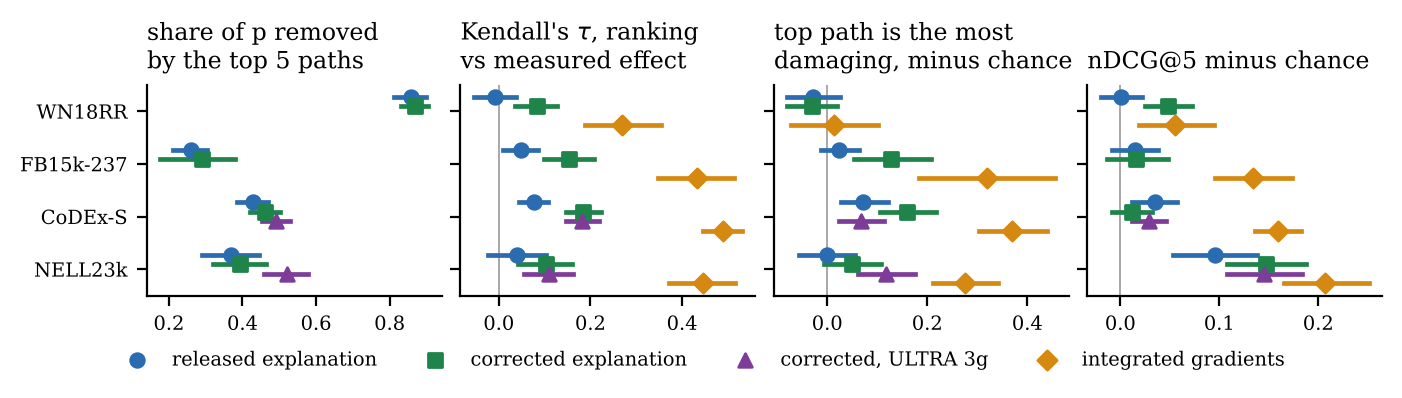

`report/figs/dose_response.pdf`

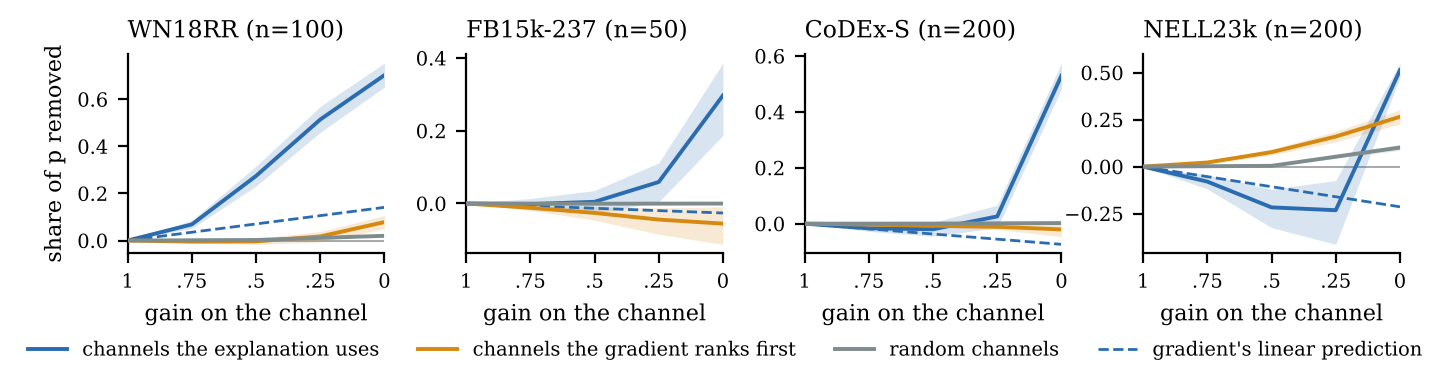

### More figures from the same results

`report/figs/set_level.pdf`

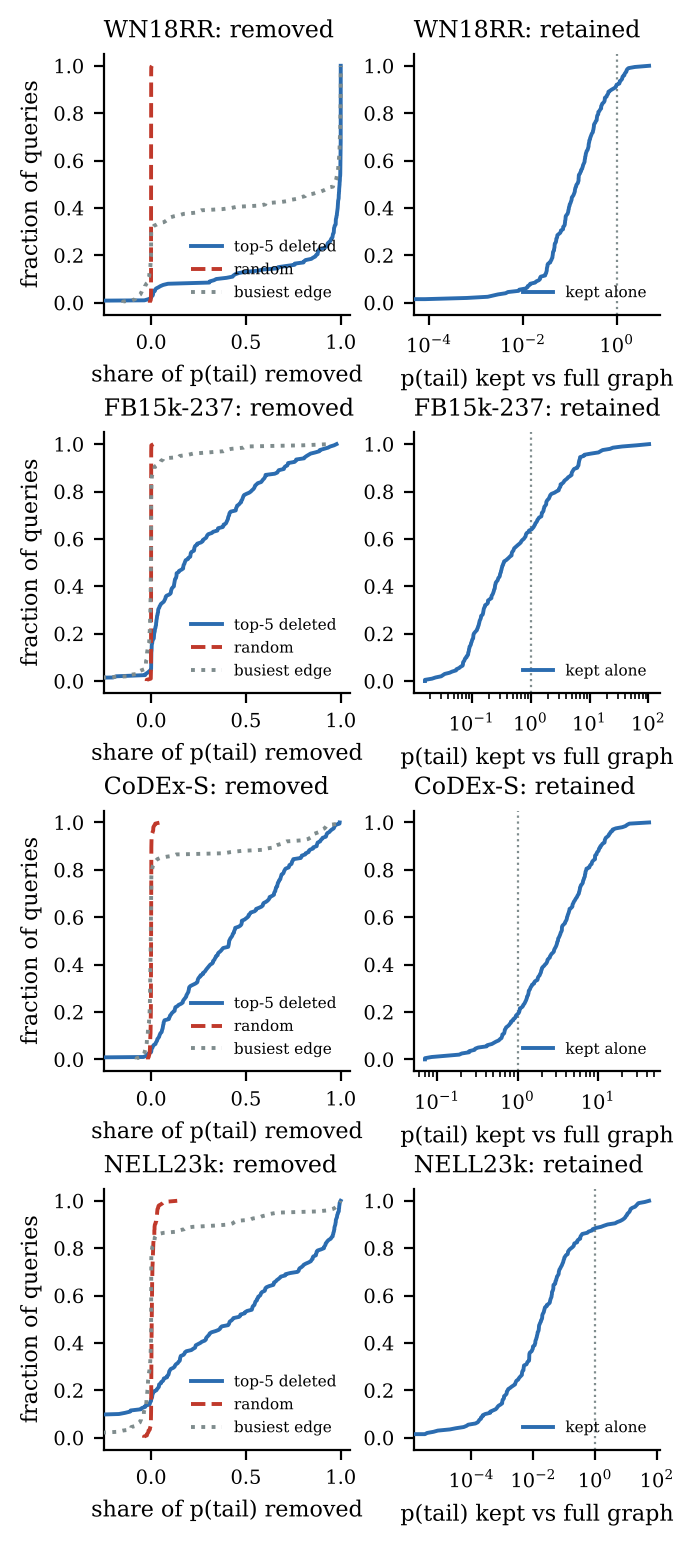

`report/figs/redundancy.pdf`

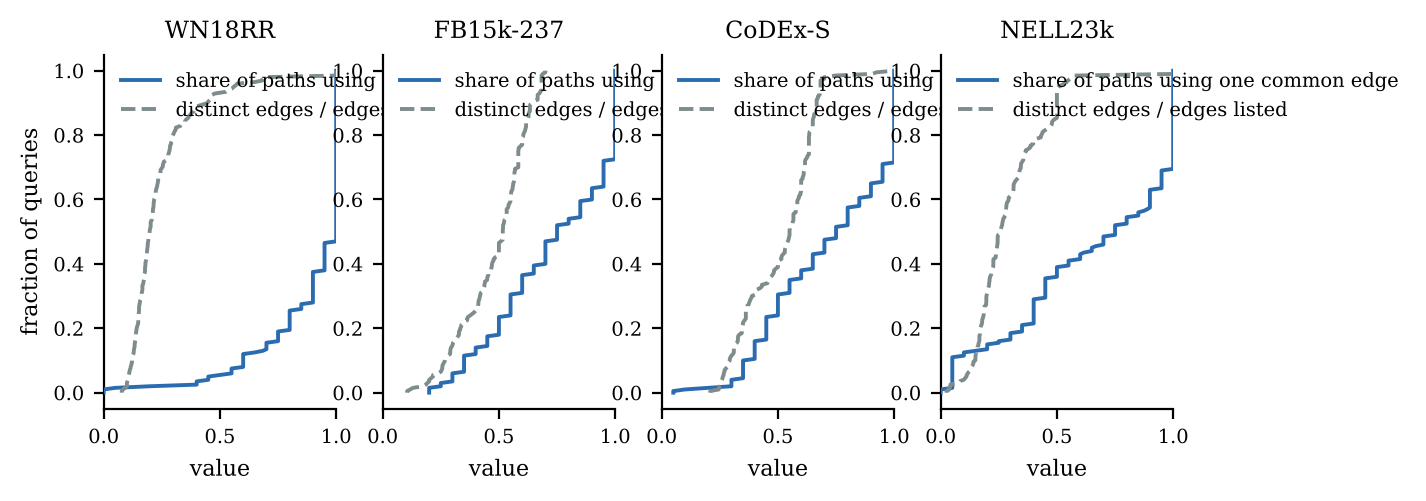

`report/figs/released_vs_corrected.pdf`

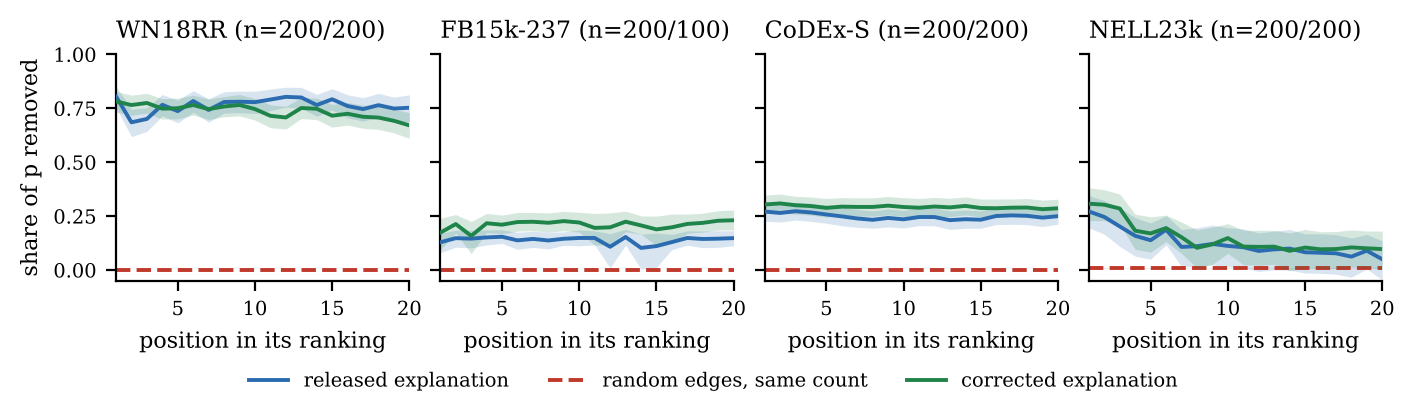

`report/figs/rank_heatmap.pdf`

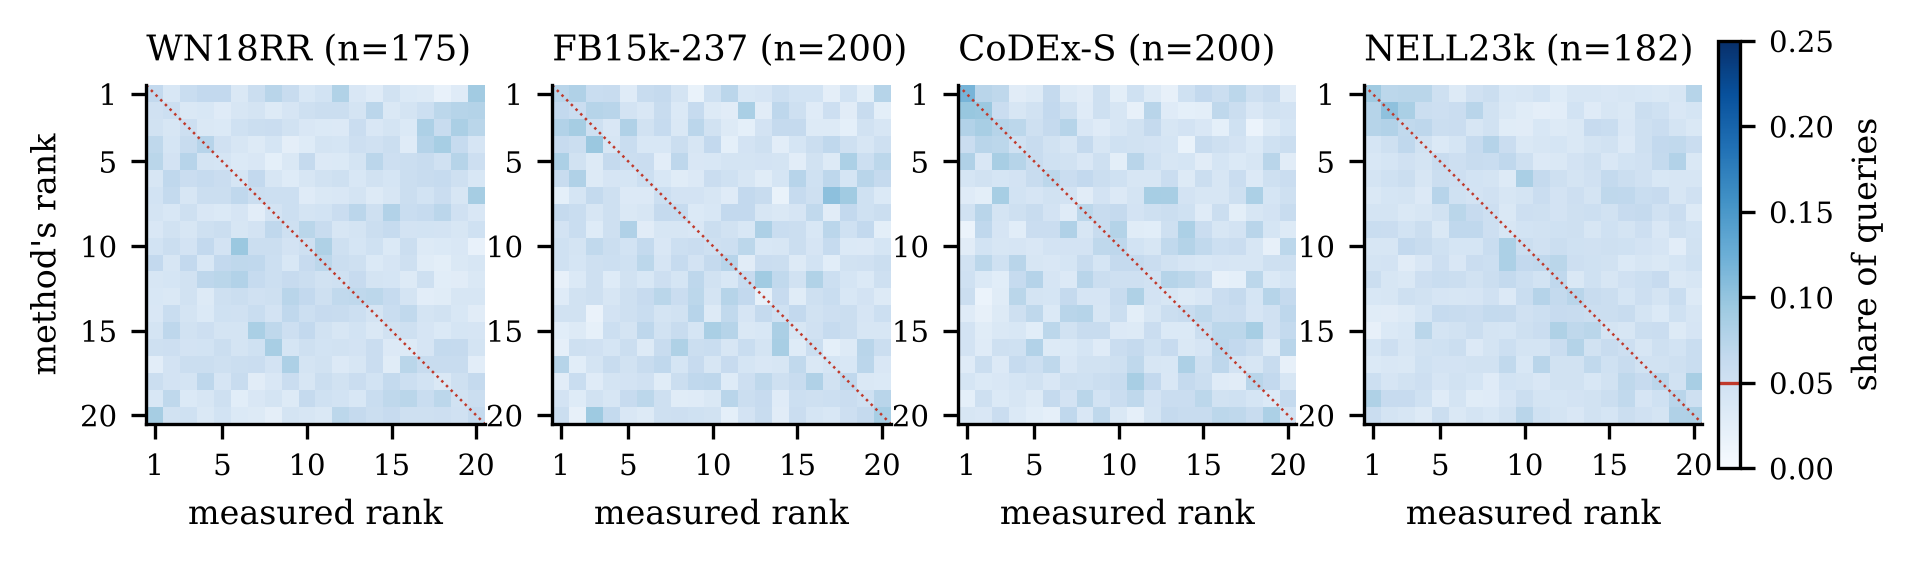

`report/figs/rank_heatmap_corrected.pdf`

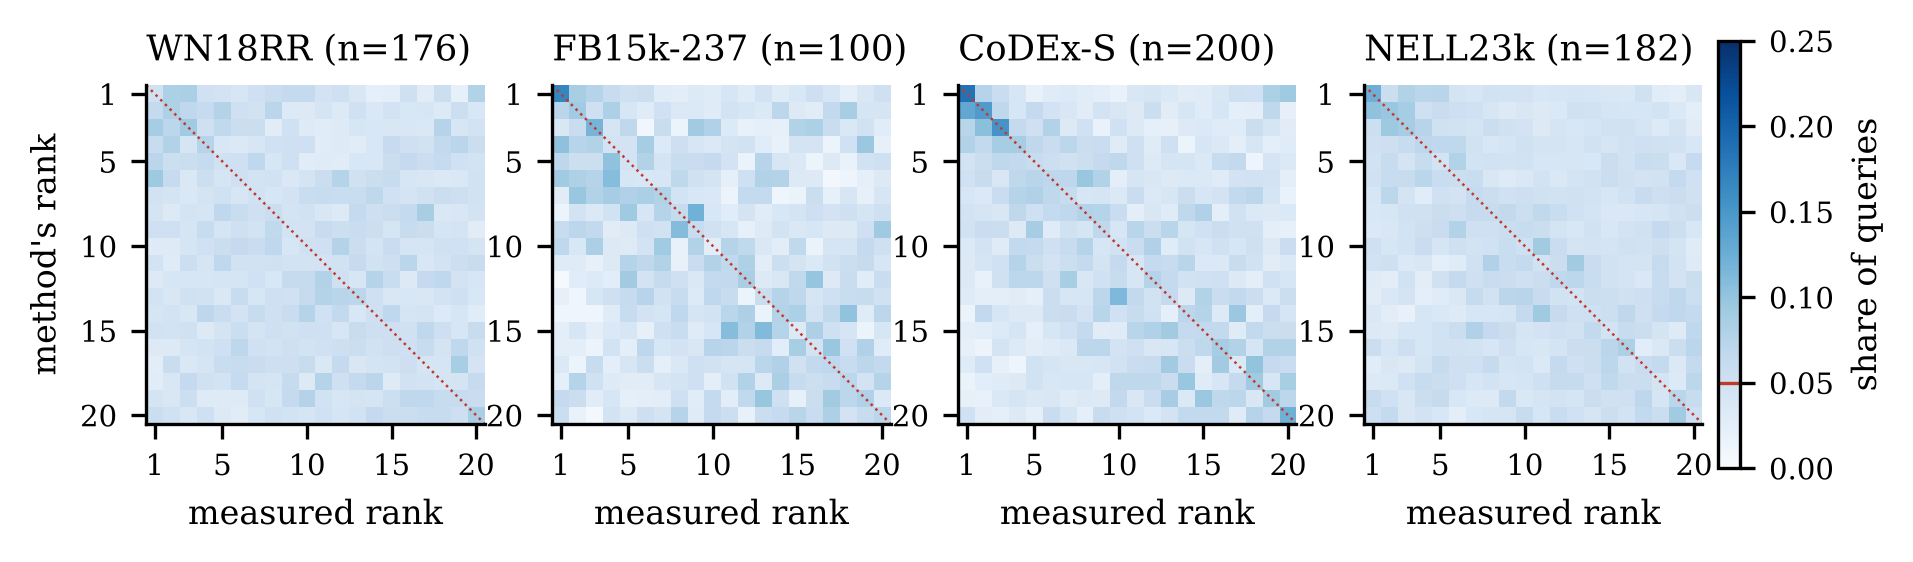

`report/figs/channels.pdf`

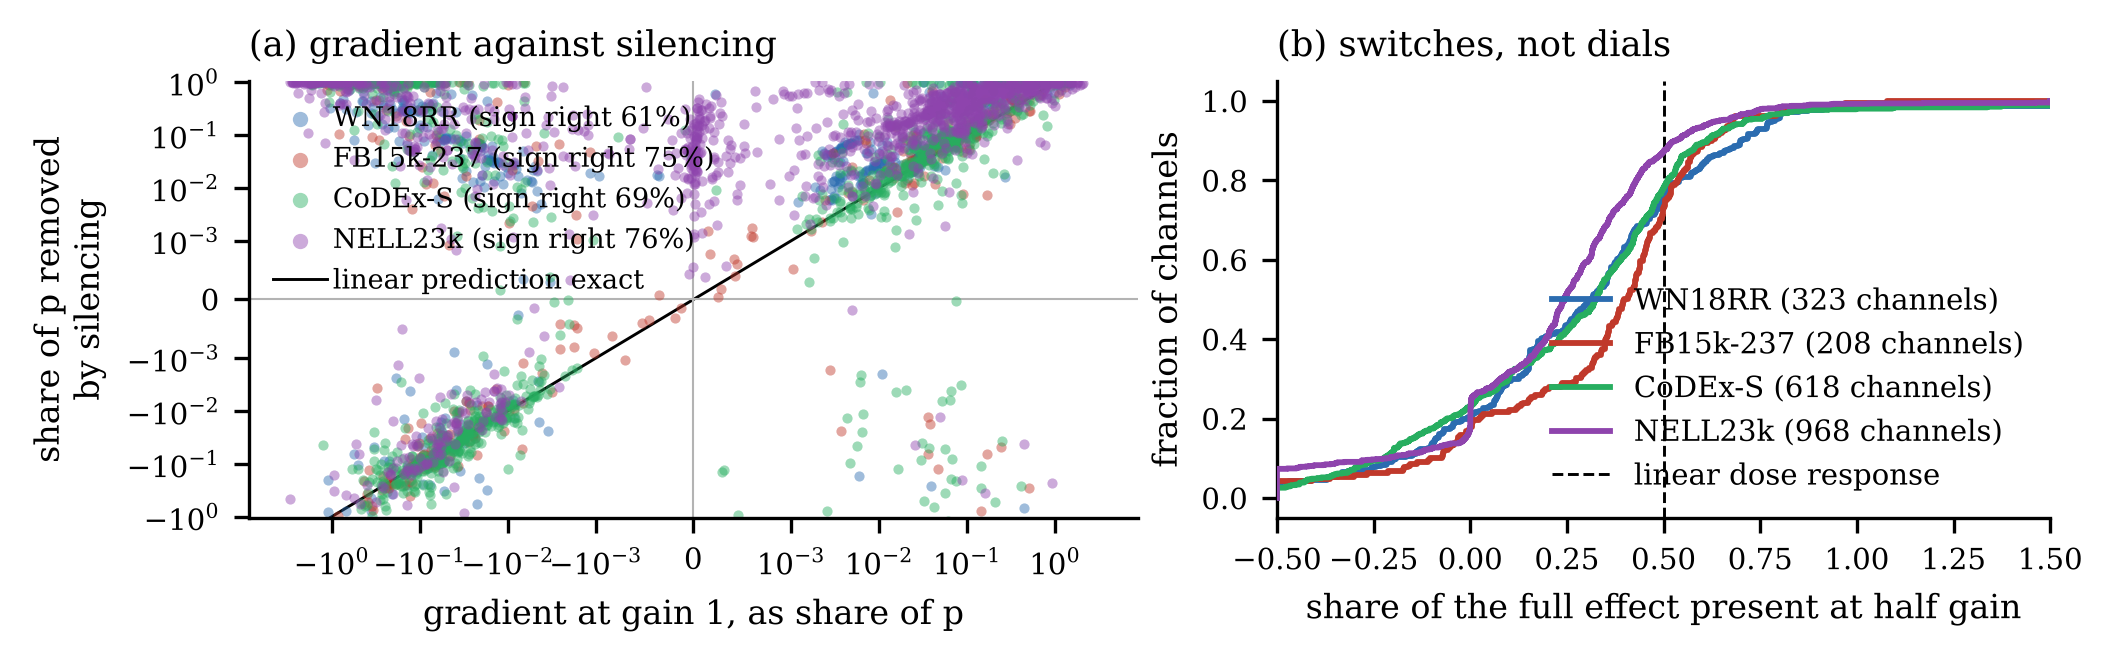

`report/figs/ig.pdf`

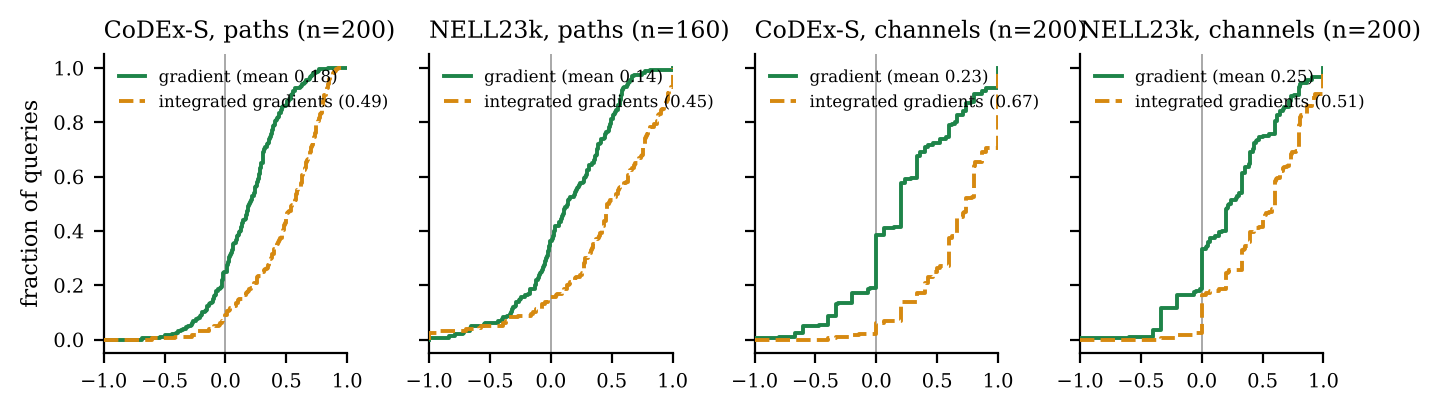

### Slide versions, the same figures at slide size

presentation/figs/channels_big.pdf
presentation/figs/convergence_big.pdf
presentation/figs/direction_big.pdf
presentation/figs/dose_response_big.pdf
presentation/figs/ig_big.pdf
presentation/figs/rank_heatmap_big.pdf
presentation/figs/rank_heatmap_corrected_big.pdf
presentation/figs/rank_vs_drop_fb15k237.pdf
presentation/figs/rank_vs_drop_wn18rr.pdf
presentation/figs/redundancy_fb15k237.pdf
presentation/figs/redundancy_wn18rr.pdf
presentation/figs/released_vs_corrected_big.pdf
presentation/figs/robustness_big.pdf


In [16]:
!python -m pathfaith.figures > /dev/null          # PDFs
!python -m pathfaith.figures --png > /dev/null    # PNGs to show here
!zip -qr figures.zip report/figs presentation/figs
import glob
from IPython.display import Image, Markdown, display
print(len(glob.glob('report/figs/*.pdf')), 'report figures and', len(glob.glob('presentation/figs/*.pdf')), 'slide figures written')

display(Markdown('### In the report'))
for name in ['direction', 'convergence', 'rank_vs_drop', 'robustness', 'dose_response']:
    display(Markdown(f'`report/figs/{name}.pdf`'))
    display(Image(f'report/figs/{name}.png', width=950))
display(Markdown('### More figures from the same results'))
for name in ['set_level', 'redundancy', 'released_vs_corrected', 'rank_heatmap', 'rank_heatmap_corrected', 'channels', 'ig']:
    display(Markdown(f'`report/figs/{name}.pdf`'))
    display(Image(f'report/figs/{name}.png', width=950))
display(Markdown('### Slide versions, the same figures at slide size'))
for f in sorted(glob.glob('presentation/figs/*.pdf')):
    print(f)

## 6. The longer runs

Everything in `results/` came from these runs. They take about a day on a CPU, so they're off.

In [17]:
RUN_EVERYTHING = False

base = '--pool 20 --topk 5 --seed 0 --path-controls 0'
runs = []
for ds, lc in [('WN18RR', 'wn18rr'), ('FB15k237', 'fb15k237'), ('CoDExSmall', 'codexsmall'), ('NELL23k', 'nell23k')]:
    f = f'results/paths_{lc}_seed0.jsonl'                      # as released
    runs += [f'run_experiment --dataset {ds} --n 200 {base} --out {f}', f'enrich --dataset {ds} --file {f}']
for ds, lc, n in [('WN18RR', 'wn18rr', 200), ('FB15k237', 'fb15k237', 100), ('CoDExSmall', 'codexsmall', 200), ('NELL23k', 'nell23k', 200)]:
    f = f'results/paths_{lc}_fixed_seed0.jsonl'                # with the fix
    runs += [f'run_experiment --dataset {ds} --n {n} {base} --corrected --out {f}', f'enrich --dataset {ds} --file {f}']
for ds, lc in [('CoDExSmall', 'codexsmall'), ('NELL23k', 'nell23k')]:
    f = f'results/paths_{lc}_3g_fixed_seed0.jsonl'             # fix + ULTRA paper's checkpoint
    runs += [f'run_experiment --dataset {ds} --n 200 {base} --corrected --ckpt ultra_3g.pth --out {f}', f'enrich --dataset {ds} --file {f}']
runs += [f'neuromod --dataset {ds} --n {n}'                    # neuromodulation
         for ds, n in [('CoDExSmall', 200), ('NELL23k', 200), ('WN18RR', 100), ('FB15k237', 50)]]
runs += [f'ig --dataset {ds} --n {n}'                          # integrated gradients
         for ds, n in [('CoDExSmall', 200), ('NELL23k', 200), ('WN18RR', 100), ('FB15k237', 50)]]
runs += ['ig --dataset CoDExSmall --n 50 --steps 32 --out results/ig_codexsmall_steps32_seed0.jsonl',   # step ablation
         'ig --dataset CoDExSmall --n 50 --steps 64 --out results/ig_codexsmall_steps64_seed0.jsonl',
         'ig --dataset CoDExSmall --n 30 --released',                                                 # released gradient
         'direction_check --dataset CoDExSmall --n 30',                                               # the bug
         'direction_check --dataset NELL23k --n 20']
runs += [f'run_baseline --dataset {ds} --ckpt {ck} --n {n} --batch-size 8 --out results/{out}'        # link prediction
         for ds, ck, n, out in [('CoDExSmall', 'ultra_4g.pth', 0, 'baseline_codexsmall.json'),
                                ('WN18RR', 'ultra_4g.pth', 0, 'baseline_wn18rr_full.json'),
                                ('FB15k237', 'ultra_4g.pth', 2000, 'baseline_fb15k237_2000.json'),
                                ('NELL23k', 'ultra_4g.pth', 0, 'baseline_nell23k_full.json'),
                                ('CoDExSmall', 'ultra_3g.pth', 0, 'baseline3g_codexsmall_full.json'),
                                ('NELL23k', 'ultra_3g.pth', 0, 'baseline3g_nell23k_full.json')]]
runs += ['reliability', 'figures']                             # reliability + figures

if RUN_EVERYTHING:
    for cmd in runs:
        print('>>', cmd, flush=True)
        !python -m pathfaith.{cmd}
else:
    print(len(runs), 'runs, switched off: set RUN_EVERYTHING = True to run them')

41 runs, switched off: set RUN_EVERYTHING = True to run them
